# Jobs

A job node is started by hand and works in the background. Run never starts it:
its own Start button does. It reports as it goes, so a card or a plot fills in
while it works. This notebook builds a job that works in steps, a job that is
one call, and the nodes after them. It starts them from Python, with
`app.start_job`, as the Start button does, and draws what they made so you can
judge it by eye. It also stops one in the middle, and shows what a refused
start and a failing job look like.

In [1]:
# Standard library
import io
import math
import threading
from typing import override

In [2]:
# Third-party libraries
import matplotlib.pyplot as plt
from IPython import display as ipython_display

In [3]:
# Local libraries
import element_51
from element_51.engine import RunResult
from element_51.jobs import JobRefusedError
from element_51.protocol import JobUpdate

In [4]:
# Small sizes keep the saved notebook small; the jobs do not sleep
STEPS = 30
DECAY = 0.9
WAIT = 10.0
COUNT_FROM = 4

## A job in steps

A step job says how many steps there are (`steps`), makes the state they share
(`begin`) and does one step (`step`), returning the new points of its series.
The fields are its inputs. A series output grows by what each step returns.

In [5]:
class Curves(element_51.Model):
    loss: element_51.Series
    accuracy: element_51.Series


class Training(element_51.JobNode[list[float]]):
    epochs: int = STEPS

    @override
    def steps(self) -> int:
        return self.epochs

    @override
    def begin(self) -> list[float]:
        return [1.0]

    @override
    def step(self, state: list[float], i: int) -> Curves:
        del i
        state[0] *= DECAY
        return Curves(
            loss=element_51.Series(values=(state[0],)),
            accuracy=element_51.Series(values=(1.0 - state[0],)),
        )


app = element_51.App([Training])
n_training = app.add_node(Training, x=60.0, y=80.0)
n_plot = app.add_node(element_51.PlotNode, x=360.0, y=80.0)
app.add_link(n_training, "loss", n_plot, "series_1")
app.add_link(n_training, "accuracy", n_plot, "series_2")

states: list[str] = []
finished = threading.Event()


def listen(event: object) -> None:
    if isinstance(event, JobUpdate):
        states.append(event.state)
        if event.state == "finished":
            finished.set()


app.subscribe_jobs(listen)
before = {o.node: o.status for o in app.execute().outcomes}
print("a plain run before Start:", before)
assert before[n_training] == "skipped"
assert before[n_plot] == "skipped"

a plain run before Start: {'n1': 'skipped', 'n2': 'skipped'}


A plain run leaves the job and the plot after it skipped. Start runs the job:

In [6]:
app.start_job(n_training)
assert finished.wait(WAIT)
print("states heard:", states[0], "...", states[-1])
results = app.run()
loss = results[n_training]["loss"]
accuracy = results[n_training]["accuracy"]
assert isinstance(loss, element_51.Series)
assert isinstance(accuracy, element_51.Series)
print(
    len(loss.values), "points of loss and", len(accuracy.values), "of accuracy"
)
assert states[0] == "running"
assert states[-1] == "finished"
assert len(loss.values) == STEPS
assert len(accuracy.values) == STEPS
assert math.isclose(loss.values[0], DECAY)
assert math.isclose(loss.values[-1], DECAY**STEPS)

states heard: running ... finished
30 points of loss and 30 of accuracy


Both curves, as the Plot card draws them:

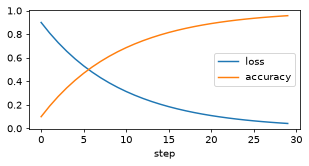

In [7]:
figure, axis = plt.subplots(figsize=(5, 2.2))
axis.plot(loss.values, label="loss")
axis.plot(accuracy.values, label="accuracy")
axis.set_xlabel("step")
axis.legend()
buffer = io.BytesIO()
figure.savefig(buffer, format="png", dpi=70, bbox_inches="tight")
plt.close(figure)
ipython_display.display(ipython_display.Image(data=buffer.getvalue()))
assert loss.values[0] > loss.values[-1]
assert accuracy.values[0] < accuracy.values[-1]

## Stopping a job

Stop ends a step job before its next step. Here the job waits at step 3, so
the notebook can press Stop while it works. The card would say `stopping`, then
`stopped`. What the job made so far stays.

In [8]:
class Gate:
    entered = threading.Event()
    release = threading.Event()


class Waiting(element_51.JobNode[None]):
    stop_after: int = 3

    @override
    def steps(self) -> int:
        return STEPS

    @override
    def begin(self) -> None:
        return None

    @override
    def step(self, state: None, i: int) -> Curves:
        del state
        if i == self.stop_after:
            Gate.entered.set()
            assert Gate.release.wait(WAIT)
        return Curves(
            loss=element_51.Series(values=(1.0 / (i + 1),)),
            accuracy=element_51.Series(values=(i / STEPS,)),
        )


stoppable = element_51.App([Waiting])
n_waiting = stoppable.add_node(Waiting, x=60.0, y=80.0)
heard: list[JobUpdate] = []
ended = threading.Event()


def listen_stop(event: object) -> None:
    if isinstance(event, JobUpdate):
        heard.append(event)
        if event.state == "stopped":
            ended.set()


stoppable.subscribe_jobs(listen_stop)
stoppable.start_job(n_waiting)
assert Gate.entered.wait(WAIT)
stoppable.stop_job(n_waiting)
print("right after Stop:", stoppable.job_states()[0].state)
Gate.release.set()
assert ended.wait(WAIT)
last = heard[-1]
print("at the end:", last.state, "after", last.step, "of", last.steps, "steps")
assert [s.state for s in heard if s.state == "stopping"] == ["stopping"]
assert last.state == "stopped"
assert last.step == Waiting().stop_after + 1
kept = last.shown["loss"]
assert isinstance(kept, element_51.Series)
assert len(kept.values) == last.step

right after Stop: stopping
at the end: stopped after 4 of 30 steps


## A job in one call, and the node after it

A job that cannot be split into steps defines `work` and calls `report`. A node
after a job sees its latest values, and runs once more when the job ends.

In [9]:
class Countdown(element_51.JobNode[None]):
    @override
    def work(self, report: element_51.Report) -> int:
        for number in range(COUNT_FROM, 0, -1):
            report(out=number)
        return 0


@element_51.node
def double(value: int) -> int:
    return value * 2


counting = element_51.App([Countdown, double])
n_countdown = counting.add_node(Countdown, x=60.0, y=80.0)
n_double = counting.add_node(double, x=320.0, y=80.0)
counting.add_link(n_countdown, "out", n_double, "value")
done = threading.Event()
runs: list[RunResult] = []


def listen_count(event: object) -> None:
    if isinstance(event, RunResult):
        runs.append(event)
        done.set()


counting.subscribe_jobs(listen_count)
counting.start_job(n_countdown)
assert done.wait(WAIT)
after = runs[0]
print("run after the job: partial =", after.partial)
print({o.node: (o.status, dict(o.outputs)) for o in after.outcomes})
assert after.partial
assert [o.node for o in after.outcomes] == [n_double]
assert after.outcomes[0].outputs == {"out": 0}
assert counting.run()[n_countdown]["out"] == 0

run after the job: partial = True
{'n2': ('ok', {'out': 0})}


## A refusal, and a job that fails

A start that cannot work is refused with a reason. A job that raises ends
`failed`, with the reason, and the editor goes on.

In [10]:
refused = False
try:
    counting.start_job(n_double)
except JobRefusedError as error:
    refused = True
    print("refused:", error.reason)
assert refused


class Boom(element_51.JobNode[None]):
    @override
    def work(self, report: element_51.Report) -> int:
        report(out=1)
        msg = "the loss blew up"
        raise RuntimeError(msg)


crashing = element_51.App([Boom])
n_boom = crashing.add_node(Boom, x=60.0, y=80.0)
failed = threading.Event()
reasons: list[str] = []


def listen_fail(event: object) -> None:
    if isinstance(event, JobUpdate) and event.state == "failed":
        reasons.append(event.error or "")
        failed.set()


crashing.subscribe_jobs(listen_fail)
crashing.start_job(n_boom)
assert failed.wait(WAIT)
print("failed:", reasons[0])
assert reasons == ["RuntimeError: the loss blew up"]
assert crashing.job_states()[0].outputs == {"out": 1}

refused: Node n2 (double) is not a job
failed: RuntimeError: the loss blew up


## A job in its own process

Set `isolated = True` and the job runs in a separate process. Stop asks, and
half a second later kills the process if the job has not ended, so even a job
that sleeps 30 s and never reports stops at once. The class must be importable
by module and name, so one typed into a notebook is refused:

In [11]:
# Standard library
import importlib
import sys
import time
from pathlib import Path

In [12]:
class Typed(element_51.JobNode[None]):
    isolated = True

    @override
    def work(self, report: element_51.Report) -> int:
        return 0


typed = element_51.App([Typed])
n_typed = typed.add_node(Typed, x=60.0, y=80.0)
reason = ""
try:
    typed.start_job(n_typed)
except JobRefusedError as error:
    reason = error.reason
    print("refused:", reason)
assert "interactive" in reason

refused: Typed is defined in an interactive session (a notebook or a prompt), so a separate process cannot import it; define it in a script or a module


The same class in a module Python can find (written to a scratch folder here) runs:

In [13]:
MODULE = """\
import time
from typing import override

import element_51


class Sleepy(element_51.JobNode[None]):
    isolated = True

    @override
    def work(self, report: element_51.Report) -> int:
        time.sleep(30)
        return 0
"""
SCRATCH = Path("__data__") / "isolated"
SCRATCH.mkdir(parents=True, exist_ok=True)
(SCRATCH / "sleepy.py").write_text(MODULE)
sys.path.insert(0, str(SCRATCH.resolve()))
sleepy = importlib.import_module("sleepy")

sleeping = element_51.App([sleepy.Sleepy])
n_sleepy = sleeping.add_node(sleepy.Sleepy, x=60.0, y=80.0)
sleepy_states: list[str] = []
ended = threading.Event()


def listen_sleepy(event: object) -> None:
    if isinstance(event, JobUpdate):
        sleepy_states.append(event.state)
        if event.state == "stopped":
            ended.set()


sleeping.subscribe_jobs(listen_sleepy)
sleeping.start_job(n_sleepy)
time.sleep(0.5)
pressed = time.monotonic()
sleeping.stop_job(n_sleepy)
assert ended.wait(WAIT)
took = time.monotonic() - pressed
print("states sleepy_states:", sleepy_states)
print("stopped within a second:", took < 1.0)
assert took < 1.0
assert sleepy_states[-1] == "stopped"

states sleepy_states: ['running', 'stopping', 'stopped']
stopped within a second: True
